<a href="https://colab.research.google.com/github/recxdivist/ocean_lab/blob/main/Lab01_Salnity_KTvD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/recxdivist/ocean_lab/blob/main/Lab01_Salnity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="toc"></a>
**Оглавление**

- [Lab01 — sprint 1](#s1)
  - [Random Variable 01 — Salnty](#rv1)
    - [Description](#rv1-desc)
    - [EDA & Distribution](#rv1-eda)
    - [Distribution: математическая база](#rv1-dist)
    - [Independence & Estimations](#rv1-est)
    - [Sampling: с возвращением и без](#rv1-sampling)
    - [Hypothesis testing](#rv1-hyp)
    - [Resume](#rv1-resume)
  - [Lab resume (sprint 1)](#s1-table)
- [Lab01 — sprint 2](#s2)
  - [random 01 — Salnty](#rv2)
    - [Description](#rv2-desc)
    - [math desc](#rv2-math)
    - [code](#rv2-code)
    - [tests](#rv2-tests)
    - [resume](#rv2-resume)
  - [Lab resume (sprint 2)](#s2-table)
- [Литература](#refs)

**Обозначения.** $N$ — объём генеральной совокупности (все непустые значения `Salnty`), $n$ — объём выборки, $x_i$ — наблюдения, $\mu,\ \sigma^2$ — параметры генеральной совокупности, $\bar x,\ s^2$ — выборочные оценки, $\varphi(x;\mu,\sigma)$ — плотность $\mathcal N(\mu,\sigma^2)$.

<a id="s1"></a>
# Lab01 — sprint 1

<a id="rv1"></a>
## Random Variable 01 — Salnty
Оформил: Довженко Александр

<a id="rv1-desc"></a>
### Description

**Данные.** Датасет CalCOFI (`sohier/calcofi`, таблица `bottle.csv`): измерения по пробам воды из батометров на океанографических станциях. Величина — столбец `Salnty`, практическая солёность по шкале PSS-78 (безразмерная, принято записывать в PSU).

**Почему эта величина — случайная.** Значение солёности в конкретной точке в конкретный момент времени определяется множеством факторов: испарением, осадками, речным стоком, течениями и турбулентным перемешиванием водных масс. Не существует детерминированной формулы $S = f(\text{координаты},\ \text{глубина},\ \text{время})$, дающей значение без остатка — солёность получают только измерением (CTD-зонд, батометр).

Следующие два графика показывают это на данных: разброс значений на одной и той же глубине и разброс на одной станции от рейса к рейсу.

In [ ]:
#@title Библиотеки и единый стиль графиков
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 110, 'figure.figsize': (10, 4.5), 'figure.constrained_layout.use': True,
    'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
})
BLUE, RED, ORANGE, GRAY = '#2b6cb0', '#d9534f', '#ed8936', '#718096'
XLABEL = 'Солёность, PSU'
rng = np.random.default_rng(42)

In [ ]:
#@title Загрузка данных
import kagglehub
path = kagglehub.dataset_download("sohier/calcofi")
df = pd.read_csv(path + "/bottle.csv", low_memory=False)
salinity = df['Salnty'].dropna().reset_index(drop=True)
print(f"Строк в таблице: {len(df):,}; измерений солёности: {len(salinity):,}; пропусков: {df['Salnty'].isna().sum():,}")

100%|██████████| 50.4M/50.4M [00:00<00:00, 113MB/s]

Extracting files...


Строк в таблице: 864,863; измерений солёности: 817,509; пропусков: 47,354


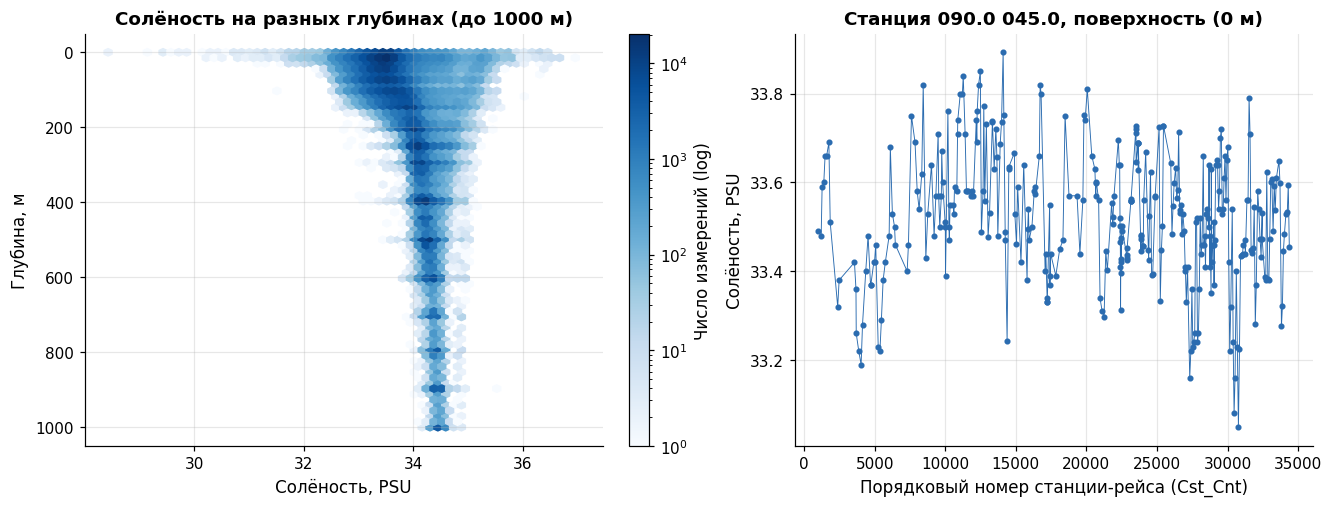

In [ ]:
#@title Разброс солёности при фиксированных условиях
d = df.loc[df.Depthm <= 1000, ['Depthm', 'Salnty']].dropna()
st = df.loc[df.Depthm == 0, 'Sta_ID'].mode()[0]
s0 = df[(df.Sta_ID == st) & (df.Depthm == 0)].dropna(subset=['Salnty'])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
hb = ax[0].hexbin(d.Salnty, d.Depthm, gridsize=60, bins='log', cmap='Blues', mincnt=1)
ax[0].invert_yaxis()
ax[0].set(xlabel=XLABEL, ylabel='Глубина, м', title='Солёность на разных глубинах (до 1000 м)')
fig.colorbar(hb, ax=ax[0], label='Число измерений (log)')
ax[1].plot(s0.Cst_Cnt, s0.Salnty, '.-', color=BLUE, lw=.6)
ax[1].set(xlabel='Порядковый номер станции-рейса (Cst_Cnt)', ylabel=XLABEL,
          title=f'Станция {st}, поверхность (0 м)')
plt.show()

*Пояснение.* Левый граффик — на любой фиксированной глубине наблюдается набор разных значений солёности, а не одно. Справа — одна станция, одна глубина, но значения от рейса к рейсу различаются.

**Сколько объясняет глубина.** Лучшая функция одной только глубины — это среднее значение солёности на данной глубине $\bar x_{d(i)}$. Её качество показывает доля объяснённой дисперсии:

$$
R^2 = 1 - \frac{\sum_i (x_i-\bar x_{d(i)})^2}{\sum_i (x_i-\bar x)^2}.
$$

In [ ]:
#@title Доля дисперсии, объяснённая глубиной
dd = df[['Depthm', 'Salnty']].dropna()
resid = dd.Salnty - dd.groupby('Depthm').Salnty.transform('mean')
r2 = 1 - (resid ** 2).sum() / ((dd.Salnty - dd.Salnty.mean()) ** 2).sum()
print(f'R² модели «солёность = среднее на данной глубине»: {r2:.3f}; не объяснено глубиной: {1 - r2:.1%}')

R² модели «солёность = среднее на данной глубине»: 0.559; не объяснено глубиной: 44.1%


*Пояснение.* Пока $R^2$ меньше 1, часть разброса остаётся даже при известной глубине. Это ещё одно подтверждение того, что солёность нельзя вычислить по формуле.


[↑ К оглавлению](#toc)

<a id="rv1-eda"></a>
### EDA & Distribution

Выборочные характеристики: среднее, дисперсия, асимметрия $\gamma_1$ и избыточный эксцесс $\gamma_2$:

$$
\bar x = \frac1n\sum_{i=1}^n x_i, \qquad
s^2 = \frac1{n-1}\sum_{i=1}^n (x_i-\bar x)^2, \qquad
\gamma_1 = \frac{m_3}{m_2^{3/2}}, \qquad
\gamma_2 = \frac{m_4}{m_2^{2}} - 3, \qquad
m_k = \frac1n\sum_{i=1}^n (x_i-\bar x)^k .
$$

In [ ]:
#@title Описательные статистики
mu, sigma = salinity.mean(), salinity.std()
var = sigma ** 2
desc = pd.Series({
    'Среднее, PSU': mu, 'Медиана, PSU': salinity.median(),
    'Дисперсия, PSU²': var, 'Стд. отклонение, PSU': sigma,
    'Асимметрия': salinity.skew(), 'Эксцесс (избыточный)': salinity.kurt(),
    'Минимум, PSU': salinity.min(), 'Максимум, PSU': salinity.max(),
}, name='Salnty')
display(desc.to_frame().style.format('{:.4f}'))

,Salnty
"Среднее, PSU",33.8404
"Медиана, PSU",33.8630
"Дисперсия, PSU²",0.2133
"Стд. отклонение, PSU",0.4618
Асимметрия,-0.0518
Эксцесс (избыточный),0.0594
"Минимум, PSU",28.4310
"Максимум, PSU",37.0340


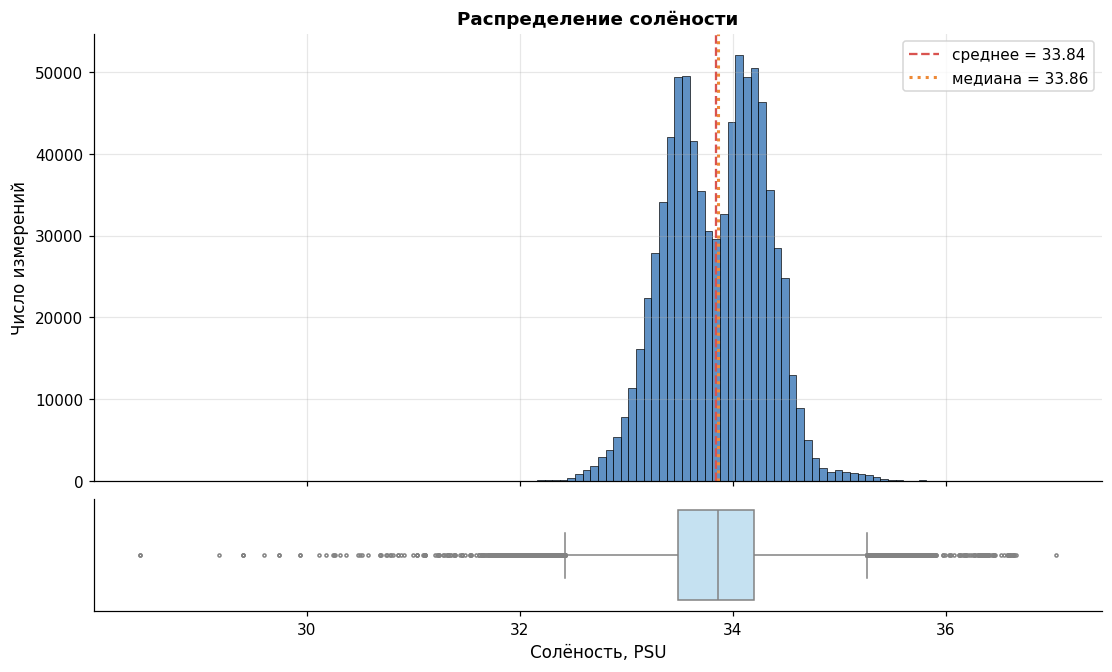

In [ ]:
#@title Гистограмма и боксплот
med = salinity.median()
fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6), gridspec_kw={'height_ratios': [4, 1]})
sns.histplot(salinity, bins=120, color=BLUE, ax=a1)
a1.axvline(mu, color=RED, ls='--', label=f'среднее = {mu:.2f}')
a1.axvline(med, color=ORANGE, ls=':', lw=2, label=f'медиана = {med:.2f}')
a1.set(ylabel='Число измерений', title='Распределение солёности')
a1.legend()
sns.boxplot(x=salinity, color='#bee3f8', fliersize=2, ax=a2)
a2.set(xlabel=XLABEL, yticks=[])
a2.grid(False)
plt.show()

*Пояснение.* На гистограмме два пика (около 33,5 и 34,2 PSU) и провал между ними около 33,8 PSU; в это углубление как раз попадают среднее и медиана. На ящике с усами выбросы с обеих сторон, левый хвост длиннее.

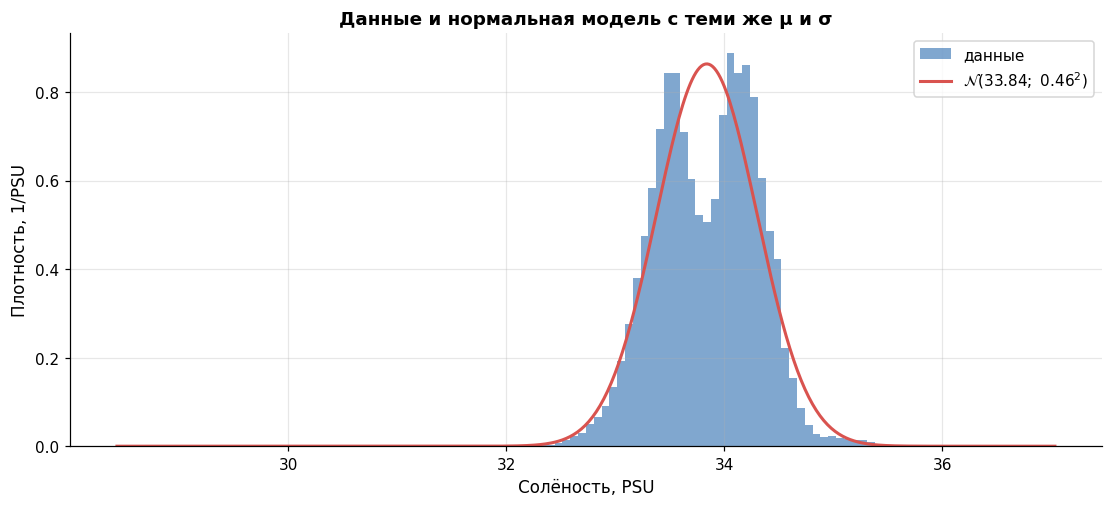

In [ ]:
#@title Сравнение с нормальным законом
x = np.linspace(salinity.min(), salinity.max(), 500)
fig, ax = plt.subplots()
ax.hist(salinity, bins=120, density=True, color=BLUE, alpha=.6, label='данные')
ax.plot(x, stats.norm.pdf(x, mu, sigma), color=RED, lw=2, label=f'$\\mathcal{{N}}({mu:.2f};\\ {sigma:.2f}^2)$')
ax.set(xlabel=XLABEL, ylabel='Плотность, 1/PSU', title='Данные и нормальная модель с теми же μ и σ')
ax.legend()
plt.show()

*Пояснение.* Нормальная кривая с теми же $\mu$ и $\sigma$ закрывает углубление между пиками и не воспроизводит сами пики.

**Квантили и выбросы.** Выбросом считаем наблюдение вне интервала

$$
\left[\,Q_1 - 1.5\,\mathrm{IQR},\ \ Q_3 + 1.5\,\mathrm{IQR}\,\right], \qquad \mathrm{IQR} = Q_3 - Q_1 .
$$

In [ ]:
#@title Квантили и выбросы по правилу IQR
qs = [.01, .05, .25, .5, .75, .95, .99]
qt = salinity.quantile(qs)
qt.index = [f'Q{q * 100:g}%' for q in qs]
display(qt.to_frame('PSU').T.style.format('{:.4f}'))

q1, q3 = qt['Q25%'], qt['Q75%']
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
below, above = (salinity < lo).sum(), (salinity > hi).sum()
print(f'Границы: [{lo:.4f}; {hi:.4f}] PSU')
print(f'Выбросов: {below + above:,} ({(below + above) / len(salinity):.2%}): ниже границы {below:,}, выше {above:,}')

,Q1%,Q5%,Q25%,Q50%,Q75%,Q95%,Q99%
PSU,32.8091,33.1140,33.4880,33.8630,34.1969,34.5200,34.8500


Границы: [32.4246; 35.2602] PSU
Выбросов: 2,550 (0.31%): ниже границы 696, выше 1,854


**Нормализация.** Стандартизация $z_i = \dfrac{x_i-\mu}{\sigma}$ переводит данные в безразмерную шкалу со средним $0$ и стандартным отклонением $1$. Она не меняет форму распределения: нормальным оно от этого не становится.

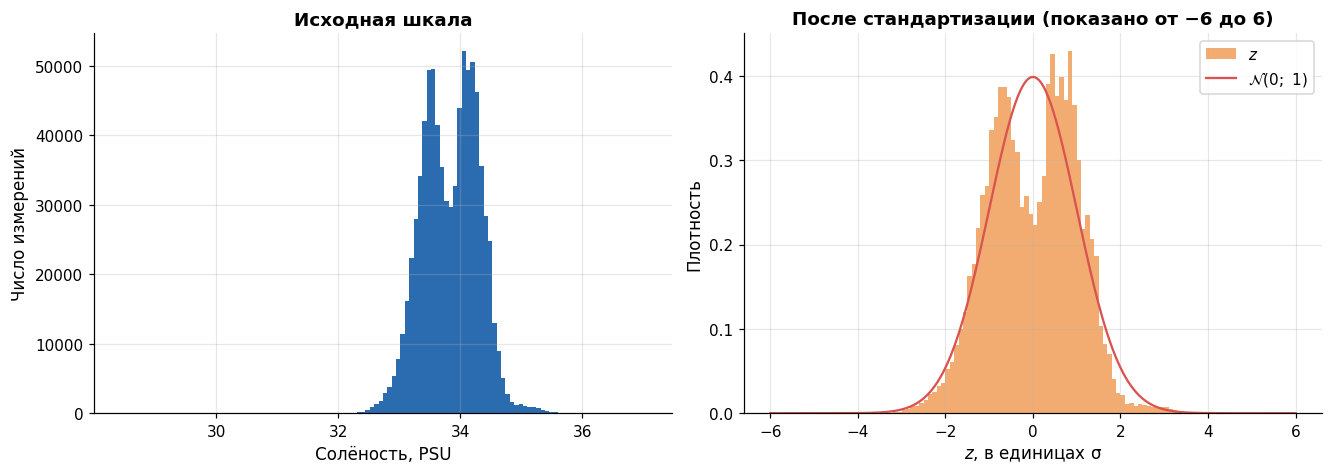

z: среднее = -1.1e-14, стд. отклонение = 1.0000


In [ ]:
#@title Стандартизация (z-преобразование)
z = (salinity - mu) / sigma
t = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(salinity, bins=120, color=BLUE)
ax[0].set(xlabel=XLABEL, ylabel='Число измерений', title='Исходная шкала')
ax[1].hist(z, bins=120, range=(-6, 6), density=True, color=ORANGE, alpha=.7, label='$z$')
ax[1].plot(t, stats.norm.pdf(t), color=RED, label=r'$\mathcal{N}(0;\ 1)$')
ax[1].set(xlabel='$z$, в единицах σ', ylabel='Плотность', title='После стандартизации (показано от −6 до 6)')
ax[1].legend()
plt.show()
print(f'z: среднее = {z.mean():.1e}, стд. отклонение = {z.std():.4f}')

*Пояснение.* Форма гистограммы сохранилась, изменились только центр и масштаб; оба пика на месте, до $\mathcal N(0;1)$ распределение не дотягивает.


[↑ К оглавлению](#toc)

<a id="rv1-dist"></a>
### Distribution: математическая база

**Нормальный закон** — модель для одной водной массы:

$$
\varphi(x;\mu,\sigma) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right).
$$

Особенности: симметричен и одновершинен ($\gamma_1 = 0,\ \gamma_2 = 0$); параметры $\mu$ и $\sigma^2$ — это среднее и дисперсия; оценки максимального правдоподобия: $\hat\mu = \bar x$, $\hat\sigma^2 = \frac1n\sum (x_i-\bar x)^2$; $P(|X-\mu|<k\sigma)\approx 0.683,\ 0.954,\ 0.997$ при $k=1,2,3$.

**Смесь двух нормальных** — модель для выборки, где смешаны воды с разными свойствами (верхние и глубинные):

$$
f(x) = p_1\,\varphi(x;\mu_1,\sigma_1) + p_2\,\varphi(x;\mu_2,\sigma_2), \qquad p_1 + p_2 = 1 .
$$

Моменты смеси:

$$
\mathbb E X = p_1\mu_1 + p_2\mu_2, \qquad
\mathrm{Var}\,X = p_1\sigma_1^2 + p_2\sigma_2^2 + p_1p_2(\mu_1-\mu_2)^2 .
$$

Последнее слагаемое — вклад различия центров компонент: поэтому дисперсия смеси больше средней дисперсии компонент. Для равных долей и равных $\sigma$ смесь двухвершинна, если $|\mu_1-\mu_2| > 2\sigma$.

Ниже выборка делится по порогу в локальном минимуме между пиками, и по каждой части оцениваются $p_k,\ \mu_k,\ \sigma_k$.

,n,доля p,"μ, PSU","σ, PSU"
Компонента 1 (< 33.84),"397,876",0.4867,33.4422,0.2555
Компонента 2 (≥ 33.84),"419,633",0.5133,34.2178,0.2467


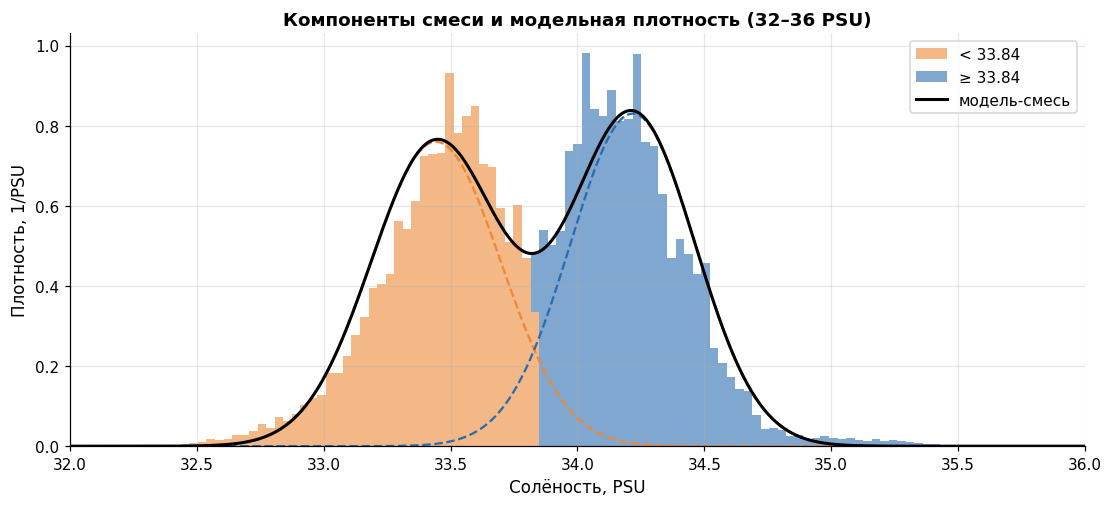

In [ ]:
#@title Разделение на две компоненты по порогу
THRESHOLD = 33.84
sal_low, sal_high = salinity[salinity < THRESHOLD], salinity[salinity >= THRESHOLD]
p1 = len(sal_low) / len(salinity)
mu1, s1, mu2, s2 = sal_low.mean(), sal_low.std(), sal_high.mean(), sal_high.std()

params = pd.DataFrame(
    {'n': [len(sal_low), len(sal_high)], 'доля p': [p1, 1 - p1], 'μ, PSU': [mu1, mu2], 'σ, PSU': [s1, s2]},
    index=[f'Компонента 1 (< {THRESHOLD})', f'Компонента 2 (≥ {THRESHOLD})'])
display(params.style.format({'n': '{:,.0f}', 'доля p': '{:.4f}', 'μ, PSU': '{:.4f}', 'σ, PSU': '{:.4f}'}))

bins = np.linspace(32, 36, 120)
x = np.linspace(32, 36, 500)
fig, ax = plt.subplots()
ax.hist([sal_low, sal_high], bins=bins, stacked=True, density=True, color=[ORANGE, BLUE], alpha=.6,
        label=[f'< {THRESHOLD}', f'≥ {THRESHOLD}'])
ax.plot(x, p1 * stats.norm.pdf(x, mu1, s1), color=ORANGE, ls='--')
ax.plot(x, (1 - p1) * stats.norm.pdf(x, mu2, s2), color=BLUE, ls='--')
ax.plot(x, p1 * stats.norm.pdf(x, mu1, s1) + (1 - p1) * stats.norm.pdf(x, mu2, s2), color='k', lw=2, label='модель-смесь')
ax.set(xlim=(32, 36), xlabel=XLABEL, ylabel='Плотность, 1/PSU', title='Компоненты смеси и модельная плотность (32–36 PSU)')
ax.legend()
plt.show()

*Пояснение.* Цветные столбцы — две части выборки (с учётом их долей), пунктир — взвешенные нормальные компоненты, а чёрная линия — их сумма. Диапазон обрезан до 32–36 PSU, остальные значения — редкие выбросы.

Чтобы проверить гипотезу о прибрежных и океанических водах, посмотрим, из каких слоёв глубины состоят пики.

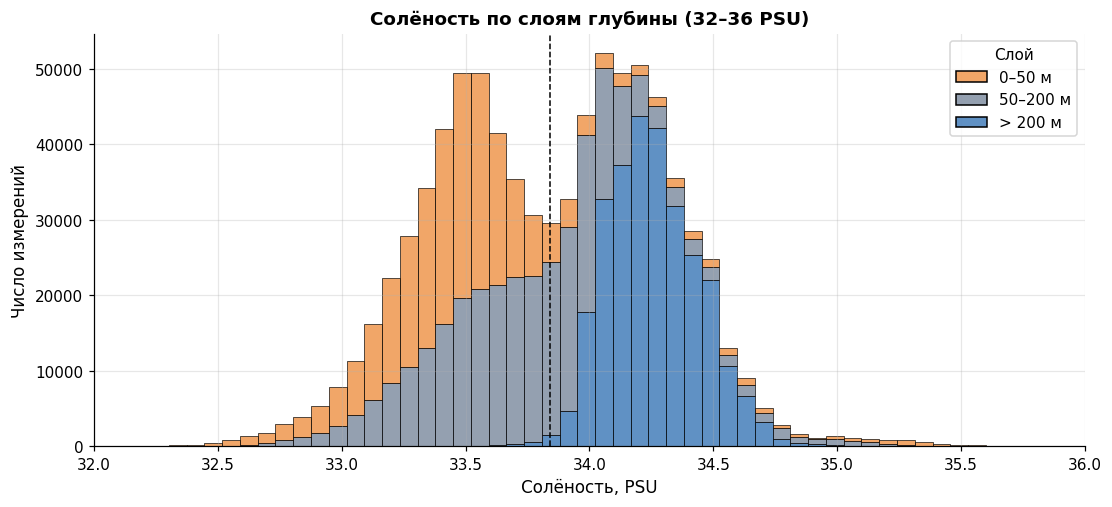

In [ ]:
#@title Солёность по слоям глубины
d = df[['Depthm', 'Salnty']].dropna().copy()
d['Слой'] = pd.cut(d.Depthm, [-1, 50, 200, np.inf], labels=['0–50 м', '50–200 м', '> 200 м'])
fig, ax = plt.subplots()
sns.histplot(d, x='Salnty', hue='Слой', multiple='stack', bins=120, palette=[ORANGE, GRAY, BLUE], ax=ax)
ax.axvline(THRESHOLD, color='k', ls='--', lw=1)
ax.set(xlim=(32, 36), xlabel=XLABEL, ylabel='Число измерений', title='Солёность по слоям глубины (32–36 PSU)')
plt.show()

*Пояснение.* Левый пик в основном состоит из верхних слоёв (0–50 и 50–200 м), правый — из слоя глубже 200 м и верхней части слоя 50–200 м. Слой 50–200 м попадает по обе стороны порога и заполняет провал между пиками. Получается, пики связаны с глубиной, а деление на прибрежные и океанические воды по этому графику не подтверждается: на нём нет координат станций. Пунктир — порог разделения.


[↑ К оглавлению](#toc)

<a id="rv1-est"></a>
### Independence & Estimations

**Независимость.** В этой части анализируется одна величина (`Salnty`), поэтому проверка независимости двух величин одной природы здесь не требуется. Пробы из одного рейса и одной станции физически связаны (одна водная толща), то есть не являются строго независимыми наблюдениями.

**Состоятельность.** Оценка $\hat\theta_n$ состоятельна, если $\hat\theta_n \xrightarrow{P} \theta$, то есть

$$
\forall \varepsilon>0:\quad P\bigl(|\hat\theta_n-\theta|>\varepsilon\bigr)\xrightarrow[n\to\infty]{}0 .
$$

Для среднего это закон больших чисел, при этом $\mathrm{Var}(\bar x_n)=\sigma^2/n$, и стандартная ошибка падает как $\sigma/\sqrt{n}$. Эмпирически: для каждого $n$ берём 200 случайных подвыборок из всей таблицы и смотрим на разброс оценок.

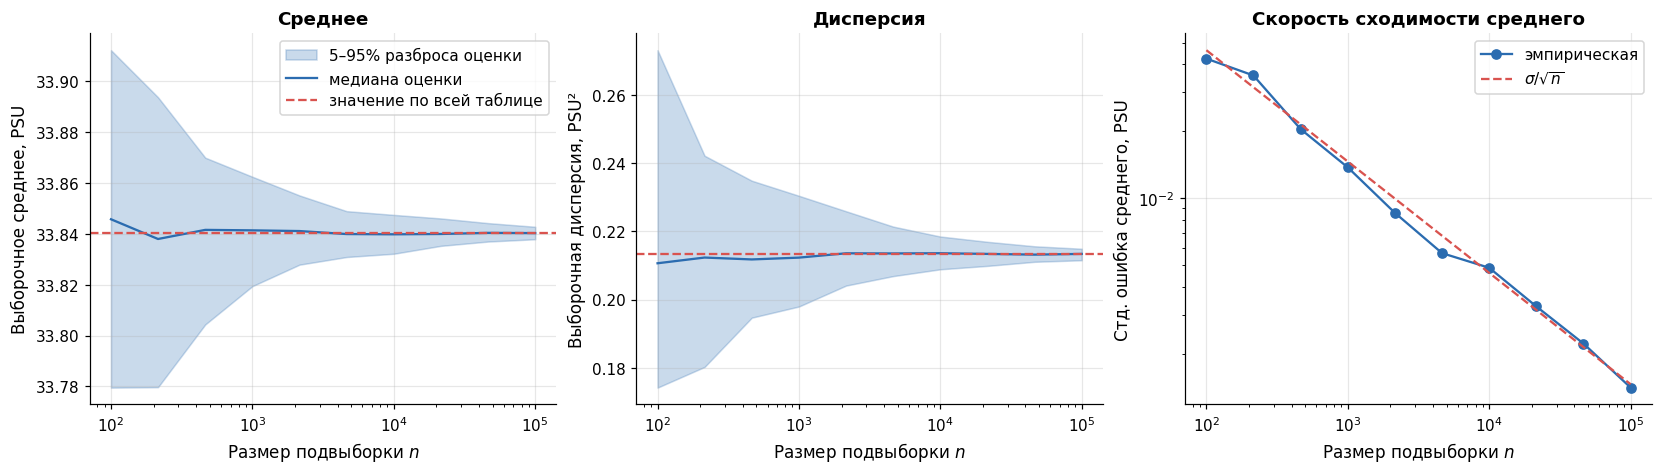

In [ ]:
#@title Состоятельность: оценки по случайным подвыборкам
x = salinity.to_numpy()
ns = np.unique(np.logspace(2, 5, 10).astype(int))
K = 200

def estimates(n):
    out = np.empty((K, 2))
    for k in range(K):
        s = rng.choice(x, n)
        out[k] = s.mean(), s.var(ddof=1)
    return out

res = np.array([estimates(n) for n in ns])

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for j, (true, ylab) in enumerate([(mu, 'Выборочное среднее, PSU'), (var, 'Выборочная дисперсия, PSU²')]):
    lo, md_, hi = np.percentile(res[:, :, j], [5, 50, 95], axis=1)
    ax[j].fill_between(ns, lo, hi, color=BLUE, alpha=.25, label='5–95% разброса оценки')
    ax[j].plot(ns, md_, color=BLUE, label='медиана оценки')
    ax[j].axhline(true, color=RED, ls='--', label='значение по всей таблице')
    ax[j].set(xscale='log', xlabel='Размер подвыборки $n$', ylabel=ylab)
ax[0].set_title('Среднее')
ax[1].set_title('Дисперсия')
ax[0].legend()
ax[2].loglog(ns, res[:, :, 0].std(axis=1), 'o-', color=BLUE, label='эмпирическая')
ax[2].loglog(ns, sigma / np.sqrt(ns), '--', color=RED, label=r'$\sigma/\sqrt{n}$')
ax[2].set(xlabel='Размер подвыборки $n$', ylabel='Стд. ошибка среднего, PSU', title='Скорость сходимости среднего')
ax[2].legend()
plt.show()

*Пояснение.* Полоска разброса обеих оценок сужается с ростом $n$, а медиана оценки сидит на значении по всей таблице — это и есть состоятельность. На правом графике (логарифмические оси) эмпирическая ошибка среднего идёт вдоль прямой $\sigma/\sqrt{n}$.


[↑ К оглавлению](#toc)

<a id="rv1-sampling"></a>
### Sampling: с возвращением и без

Генеральная совокупность — вся таблица ($N$ значений). Дисперсия выборочного среднего при $n$ наблюдениях:

$$
\text{с возвращением:}\ \ \mathrm{Var}(\bar x)=\frac{\sigma^2}{n},
\qquad
\text{без возвращения:}\ \ \mathrm{Var}(\bar x)=\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}.
$$

Множитель $\frac{N-n}{N-1}$ — поправка на конечность совокупности; при $n\ll N$ он близок к 1 и разница между схемами пропадает. Сначала сравним статистики одной выборки $n=10\,000$ с генеральными.

,"Среднее, PSU","Дисперсия, PSU²"
"Генеральная (N=817,509)",33.8404,0.2133
"Без возвращения (n=10,000)",33.8411,0.2145
"С возвращением (n=10,000)",33.8341,0.2115


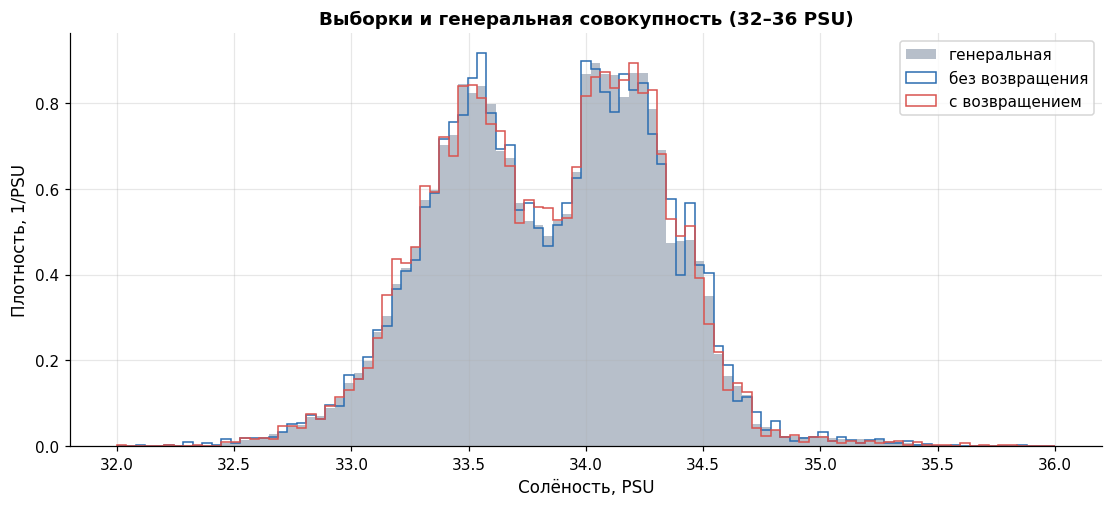

In [ ]:
#@title Статистики выборок и генеральной совокупности
n_s = 10_000
s_wo = rng.choice(x, n_s, replace=False)
s_w = rng.choice(x, n_s, replace=True)
cmp = pd.DataFrame({
    'Среднее, PSU': [mu, s_wo.mean(), s_w.mean()],
    'Дисперсия, PSU²': [var, s_wo.var(), s_w.var()],
}, index=[f'Генеральная (N={len(x):,})', f'Без возвращения (n={n_s:,})', f'С возвращением (n={n_s:,})'])
display(cmp.style.format('{:.4f}'))

fig, ax = plt.subplots()
bins = np.linspace(32, 36, 100)
ax.hist(x, bins, density=True, color=GRAY, alpha=.5, label='генеральная')
ax.hist(s_wo, bins, density=True, histtype='step', color=BLUE, lw=1.6, label='без возвращения')
ax.hist(s_w, bins, density=True, histtype='step', color=RED, lw=1.6, label='с возвращением')
ax.set(xlabel=XLABEL, ylabel='Плотность, 1/PSU', title='Выборки и генеральная совокупность (32–36 PSU)')
ax.legend()
plt.show()

*Пояснение.* Обе выборки повторяют форму генерального распределения, включая два пика, и дают близкие среднее и дисперсию.

Одна выборка не показывает разницу между схемами — она проявляется в разбросе оценки. Повторим выбор 200 раз для разных $n$, чтобы сравнить с теорией стандартное отклонение выборочного среднего.

,с возвр.,без возвр.,отношение,теория √((N−n)/(N−1))
n,,,,
1000,0.01375,0.01462,1.063,0.999
10000,0.00448,0.00458,1.021,0.994
100000,0.00149,0.00124,0.836,0.937
400000,0.00070,0.00051,0.729,0.715


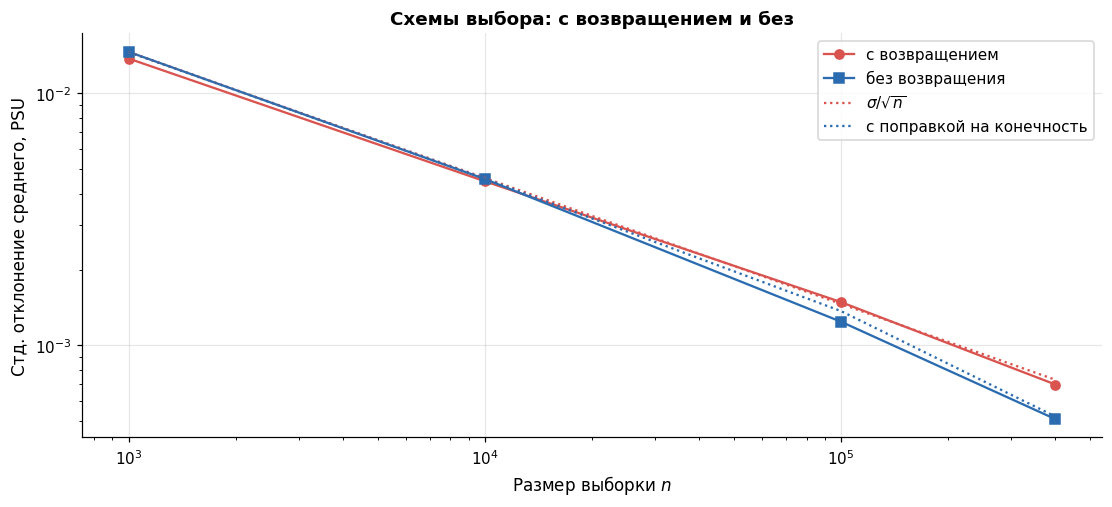

In [ ]:
#@title Разброс среднего: с возвращением и без
N, reps = len(x), 200
sizes = [1_000, 10_000, 100_000, 400_000]
rows = []
for n in sizes:
    m_w = [rng.choice(x, n).mean() for _ in range(reps)]
    m_wo = [rng.choice(x, n, replace=False).mean() for _ in range(reps)]
    rows.append((n, np.std(m_w), np.std(m_wo)))
se = pd.DataFrame(rows, columns=['n', 'с возвр.', 'без возвр.']).set_index('n')
se['отношение'] = se['без возвр.'] / se['с возвр.']
se['теория √((N−n)/(N−1))'] = np.sqrt((N - se.index) / (N - 1))
display(se.style.format({'с возвр.': '{:.5f}', 'без возвр.': '{:.5f}', 'отношение': '{:.3f}', 'теория √((N−n)/(N−1))': '{:.3f}'})
        .set_caption('Стд. отклонение выборочного среднего, PSU'))

fig, ax = plt.subplots()
ax.loglog(se.index, se['с возвр.'], 'o-', color=RED, label='с возвращением')
ax.loglog(se.index, se['без возвр.'], 's-', color=BLUE, label='без возвращения')
ax.loglog(se.index, sigma / np.sqrt(se.index), ':', color=RED, label=r'$\sigma/\sqrt{n}$')
ax.loglog(se.index, sigma / np.sqrt(se.index) * np.sqrt((N - se.index) / (N - 1)), ':', color=BLUE, label='с поправкой на конечность')
ax.set(xlabel='Размер выборки $n$', ylabel='Стд. отклонение среднего, PSU', title='Схемы выбора: с возвращением и без')
ax.legend()
plt.show()

*Пояснение.* При $n\ll N$ линии почти сливаются; при $n$, сравнимом с $N$ (к примеру, $n=400\,000$), выборка без возвращения даёт заметно меньший разброс среднего — в согласии с множителем $\sqrt{(N-n)/(N-1)}$.


[↑ К оглавлению](#toc)

<a id="rv1-hyp"></a>
### Hypothesis testing

**Гипотеза.** $H_0$: солёность распределена нормально, $X\sim\mathcal N(\mu,\sigma^2)$; $H_1$: распределение не нормальное. Критерий Андерсона–Дарлинга:

$$
A^2 = -n - \frac1n\sum_{i=1}^{n}(2i-1)\Bigl[\ln F(x_{(i)}) + \ln\bigl(1-F(x_{(n+1-i)})\bigr)\Bigr],
$$

где $x_{(1)}\le\dots\le x_{(n)}$ — упорядоченная выборка, $F$ — функция распределения $\mathcal N(\bar x, s^2)$. $H_0$ отвергается на уровне $\alpha=0.05$, если $A^2$ больше критического значения. Тест применяем к подвыборке $n=10\,000$ и отдельно к каждой из двух компонент.

**Замечание.** Из-за того что компоненты получены обрезанием выборки по порогу, каждая из них уже усечена с одной стороны — это влияет на результат теста нормальности.

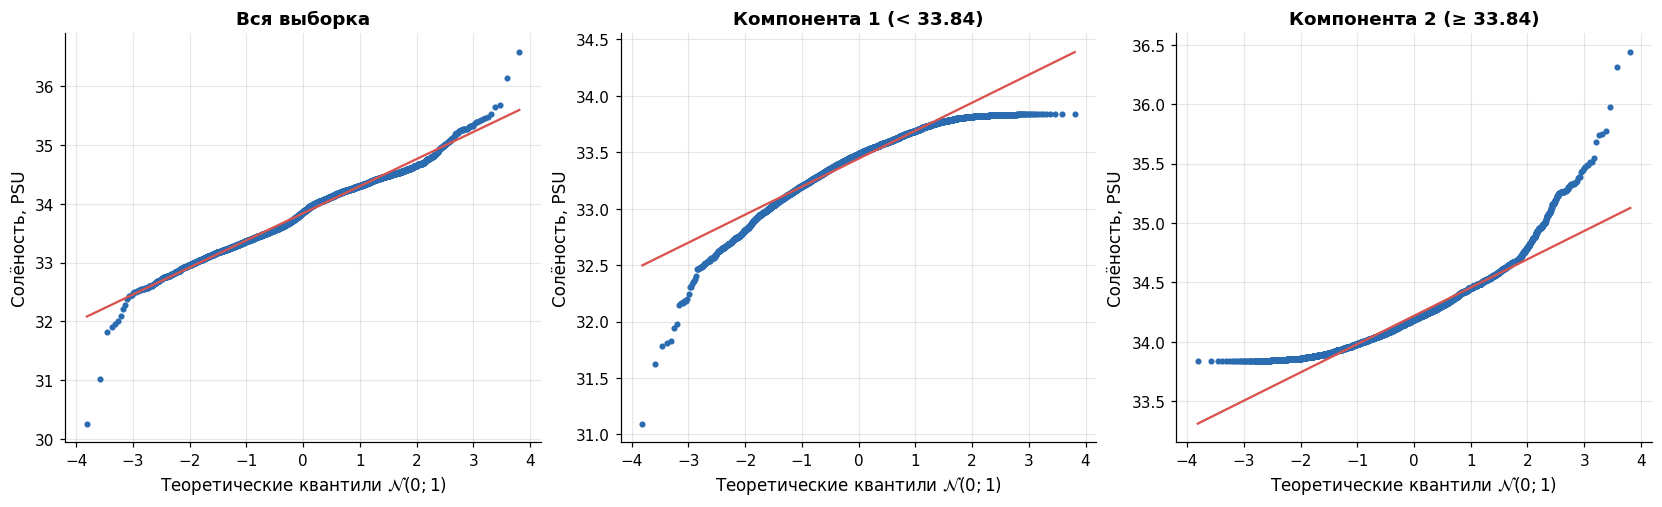

,$A^2$,крит. значение (5%),H0
Выборка,,,
Вся выборка,40.50,0.787,отвергается
Компонента 1 (< 33.84),104.27,0.787,отвергается
Компонента 2 (≥ 33.84),95.97,0.787,отвергается


In [ ]:
#@title Критерий Андерсона–Дарлинга и Q–Q графики
import warnings
groups = {'Вся выборка': salinity, f'Компонента 1 (< {THRESHOLD})': sal_low, f'Компонента 2 (≥ {THRESHOLD})': sal_high}
rows = []
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (name, g) in zip(ax, groups.items()):
    sub = g.sample(10_000, random_state=42)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        ad = stats.anderson(sub, dist='norm')
    crit = ad.critical_values[2]
    rows.append({'Выборка': name, '$A^2$': ad.statistic, 'крит. значение (5%)': crit,
                 'H0': 'отвергается' if ad.statistic > crit else 'не отвергается'})
    stats.probplot(sub, dist='norm', plot=a)
    a.get_lines()[0].set(color=BLUE, markersize=3)
    a.get_lines()[1].set(color=RED)
    a.set(title=name, xlabel='Теоретические квантили $\\mathcal{N}(0;1)$', ylabel=XLABEL)
plt.show()
display(pd.DataFrame(rows).set_index('Выборка').style.format({'$A^2$': '{:.2f}', 'крит. значение (5%)': '{:.3f}'}))

*Пояснение.* Если данные нормальны, точки Q–Q графика лежат на прямой. Отклонения в центре и на концах означают ненормальность. В таблице решение критерия для всей выборки и для каждой компоненты.


[↑ К оглавлению](#toc)

<a id="rv1-resume"></a>
### Resume

**Выводы:**

Солёность — случайная величина стохастической природы и детерминированный расчёт невозможен. Нельзя взять формулу и посчитать по ней солёность в конкретной точке и в конкретное время, влиет множемтво природных факторов (испарение, дожди, реки, течения и перемешивание воды), которые в совокупности нельзя предсказать. На графике разброса при фиксированных условиях видно, что на одной глубине встречаются разные значения, на одной станции на поверхности значения также отличаются от рейса к рейсу. Данные подтверждают, что солёность — случайная величина, которую можно только измерить.

Форма распределения: среднее 33.84, медиана 33.86, можно подумать что распределение "колоколом". Но на гистаграмме два пика, и эти значения попадают в углубление между ними, где меньше всего значений. Почти нулевая ассиметрия (-0.05) не доказывает, что распределение нормальное: два горба просто уравновешивают друг друга.

Гипотеза о нормальности. Проверяли критерием Андерсона-Дарлинга, значение получилось 40.5, критическое 0.79 (на уровне 5%). Поэтому нормальность отвергается — число значительно больше критического. Q-Q график это подтверждает: будь распределение нормальным, тоски лежали бы на прямой, а не изгибались в середине, уходя вниз на левом краю. При разделении графика по порогу гипотеза тоже отверглась, так как обе части обрезаны с одной стороны. Так что модель "смесь двух нормальных" остаётся хорошим приближением, а не точным описанием.

Пики на графике: предположили, что один горб — прибрежные, менее солёные воды, а другой — океанические, более солёные. Для проверки расположили данные по слоям глубины. Левый горб в основном состоит из верхних слоёв (0–50 и 50–200 м), правый — из слоя глубже 200 м и верхней части слоя 50–200 м, а слой 50–200 м попадает по обе стороны порога и заполняет провал между горбами. Значит, горбы связаны с глубиной (сверху вода менее солёная, снизу более солёная), а гипотеза о прибрежных и океанических водах не подтвердилась: на графике нет координат станций, поэтому проверить её по нему нельзя. Деление по порогу не равно делению по глубине, так что части получились не совсем «чистыми». В любом случае пики говорят о смеси вод с разными свойствами.

Выбросы по IQR: по правилу выбросами считаются значения вне интервала [32.42; 35.26], коих 2550 (всего 0.31% от всех измерений, очень мало). Основная масса лежит между 32.8 и 34.9. Слишком низкую солёность можно оправдать наличием пресных течений, слишком высокую — обильным испарением, поэтому такие значения, скорее всего, настоящие, а не ошибки измерения.

Состоятельность оценок: больше данных — ближе оценка к настоящему значению. На графиках видно, как с ростом выборки полоса разброса и выборочной дисперсии сужается. Ошибка среднего уменьшается как  σ/$\sqrt{n}$, для n = 10 000 она около 0.005, чего достаточно чтобы оценить среднее с хорошей точностью. Для дальнейшего уменьшения ошибки вдвое нужно вчетверо больше данных.

Выборка с возвращением и без. Выборка в 10 000 значений из 817 509 даёт близкие к генеральным среднее и дисперсию, и в обеих схемах (с возвращением и без) разницы почти нет. При выборе без возвращения разброс среднего уменьшается в $\sqrt{((N−n)/(N−1))}$ раза. При n = 10 000 это почти единица (≈ 0.99), и разницы нет. При n = 400 000 это ≈ 0.71, и выборка без возвращения заметно точнее — это видно и по таблице, и по графику. Смысл: без возвращения мы не берём одно и то же значение дважды, поэтому информации в выборке больше.

Ограничения. (1) Пробы из одной станции и одного рейса берутся из одной и той же водной толщи, поэтому они не совсем независимы, а мы считали наблюдения независимыми. (2) В таблице смешаны разные годы, места и глубины; судя по графику слоёв, два горба связаны в первую очередь с глубиной. (3) Порог 33.84 мы выбрали «на глаз» по гистограмме, а не вычислили, так что параметры частей зависят от этого выбора. (4) Границы слоёв глубины (50 и 200 м) тоже выбраны нами произвольно.

[↑ К оглавлению](#toc)

<a id="s1-table"></a>
## Lab resume (sprint 1)

<a id="cat-table-1"></a>
### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|:------:|:--------------|:-----:|:--------|
| $R^2$ | [Description](#rv1-desc) | 0.559 | Доля дисперсии солёности, объяснённая глубиной (модель «среднее на данной глубине»); остальное — разброс при одинаковой глубине |
| $s^2$<br>$x_{\min}$<br>$x_{\max}$<br>outliers<br>$\bar z$<br>$s_z$ | [EDA & Distribution](#rv1-eda) | 0.2133 PSU²<br>28.431 PSU<br>37.034 PSU<br>2550<br>≈ 0<br>1.0000 | Описательные статистики, выбросы по IQR (696 ниже границы, 1854 выше), z-преобразование |
| $$\sigma/\sqrt{n}$<br>$\mathrm{SE}(\bar x_n)$$ | [Independence & Estimations](#rv1-est) | 0.00462<br>0.00448 | Состоятельность при $n=10\,000$: теоретическая и эмпирическая ошибка среднего |
| $$\mathrm{Var}(\bar x)=\dfrac{\sigma^2}{n}$$<br>$$\mathrm{Var}(\bar x)=\dfrac{\sigma^2}{n}\cdot\dfrac{N-n}{N-1}$$ | [Sampling](#rv1-sampling) | 0.00448 / 0.00458<br>0.00070 / 0.00051 | Стд. отклонение среднего с возвращением / без при $n=10\,000$ и $n=400\,000$; поправка $\sqrt{\frac{N-n}{N-1}}$ равна 0.994 и 0.715 |
| $$\mathcal N(\mu,\sigma^2)$$<br>$$p_1\varphi_1+p_2\varphi_2$$ | [Distribution](#rv1-dist) | $\mu=33.8404,\ \sigma=0.4618$<br>$p_1=0.4867$<br>$\mu_1=33.4422,\ \sigma_1=0.2555$<br>$\mu_2=34.2178,\ \sigma_2=0.2467$ | Нормальный закон и смесь двух нормальных (порог 33.84) |
| $A^2$<br>$A^2_{\text{крит}}$ | [Hypothesis testing](#rv1-hyp) | 40.50 / 104.27 / 95.97<br>0.787 | Андерсон–Дарлинг: вся выборка / компонента 1 / компонента 2; $H_0$ о нормальности отвергается везде ($\alpha=0.05$) |


[↑ К оглавлению](#toc)

<a id="s2"></a>
# Lab01 — sprint 2

<a id="rv2"></a>
## random 01 — Salnty

<a id="rv2-desc"></a>
### Description

Распределение солёности — смесь двух нормальных законов (см. [Distribution](#rv1-dist)), поэтому генератор строится как

1. **метод суперпозиции** — случайно выбираем компоненту смеси;
2. **метод полярных координат (Бокс–Мюллер)** — генерируем нормальное число для выбранной компоненты.

Параметры $p_1,\ \mu_k,\ \sigma_k$ берём из разделения по порогу (раздел [Distribution](#rv1-dist)). Источник равномерных чисел — `numpy.random.default_rng` (PCG64).


[↑ К оглавлению](#toc)

<a id="rv2-math"></a>
### math desc

**Метод суперпозиции.** Если $F(x)=p_1F_1(x)+p_2F_2(x)$, то величину с функцией распределения $F$ получают в два шага: выбирают номер компоненты $K$ с вероятностями $P(K=k)=p_k$ и затем генерируют $X$ из $F_K$. По формуле полной вероятности

$$
P(X\le x)=\sum_{k=1}^{2}P(K=k)\,P(X\le x\mid K=k)=p_1F_1(x)+p_2F_2(x).
$$

На практике: $U_0\sim U(0,1)$; если $U_0<p_1$ — берём первую компоненту, иначе вторую.

**Метод полярных координат (Бокс–Мюллер).** Пусть $U_1,U_2\sim U(0,1)$ независимы. Тогда

$$
Z=\sqrt{-2\ln U_1}\,\cos(2\pi U_2)\ \sim\ \mathcal N(0,1),\qquad X=\mu+\sigma Z\ \sim\ \mathcal N(\mu,\sigma^2).
$$

Обоснование. Пара независимых $\mathcal N(0,1)$ имеет плотность $\frac1{2\pi}e^{-(z_1^2+z_2^2)/2}$. В полярных координатах $z_1=r\cos\theta$, $z_2=r\sin\theta$ она принимает вид $\frac1{2\pi}\,r e^{-r^2/2}$ — угол $\theta\sim U(0,2\pi)$, а радиус $R$ не зависит от него и имеет плотность $f_R(r)=re^{-r^2/2}$ и функцию распределения $F_R(r)=1-e^{-r^2/2}$. Метод обратной функции даёт $R=F_R^{-1}(V)=\sqrt{-2\ln(1-V)}$; так как $1-V\sim U(0,1)$, можно взять $R=\sqrt{-2\ln U_1}$, а $\theta=2\pi U_2$.

**Ограничения модели:**
- У нормальных компонент нет тяжёлых хвостов, а в реальных данных есть выбросы (см. [EDA](#rv1-eda)) — хвосты генератора будут отличаться.
- Параметры оценены по частям выборки, усечённым порогом, поэтому форма пиков может немного отличаться от реальной.


[↑ К оглавлению](#toc)

<a id="rv2-code"></a>
### code

In [ ]:
#@title Класс генератора
class SalinityMixtureGenerator:
    def __init__(self, mu1, s1, mu2, s2, p1, seed=None):
        self.mu1, self.s1, self.mu2, self.s2, self.p1 = mu1, s1, mu2, s2, p1
        self.rng = np.random.default_rng(seed)

    def std_normal(self, n):
        u1, u2 = self.rng.random(n), self.rng.random(n)
        return np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)

    def generate(self, n):
        first = self.rng.random(n) < self.p1
        z = self.std_normal(n)
        return np.where(first, self.mu1 + self.s1 * z, self.mu2 + self.s2 * z)

gen = SalinityMixtureGenerator(mu1, s1, mu2, s2, p1, seed=42)
generated = gen.generate(len(salinity))
print(f'Сгенерировано {len(generated):,} значений: среднее = {generated.mean():.4f}, σ = {generated.std():.4f}')

Сгенерировано 817,509 значений: среднее = 33.8405, σ = 0.4617


<a id="rv2-tests"></a>
### tests

Сравниваем метрики реальных данных и генератора. Для асимметрии и эксцесса (значения около нуля) относительная ошибка неинформативна, поэтому берём абсолютную разность.

In [ ]:
#@title Сравнение метрик
g = pd.Series(generated)
rows = {'Среднее': (salinity.mean(), g.mean()), 'Стд. отклонение': (salinity.std(), g.std()),
        'Асимметрия': (salinity.skew(), g.skew()), 'Эксцесс': (salinity.kurt(), g.kurt())}
for q in [.05, .25, .5, .75, .95]:
    rows[f'Q{q * 100:g}%'] = (salinity.quantile(q), g.quantile(q))
tbl = pd.DataFrame(rows, index=['Реальные', 'Генератор']).T
tbl['Абс. разность'] = (tbl['Генератор'] - tbl['Реальные']).abs()
display(tbl.style.format('{:.4f}'))

,Реальные,Генератор,Абс. разность
Среднее,33.8404,33.8405,0.0001
Стд. отклонение,0.4618,0.4617,0.0001
Асимметрия,-0.0518,-0.0589,0.0071
Эксцесс,0.0594,-0.9873,1.0466
Q5%,33.1140,33.1186,0.0046
Q25%,33.4880,33.4505,0.0375
Q50%,33.8630,33.8614,0.0016
Q75%,34.1969,34.2265,0.0296
Q95%,34.5200,34.5378,0.0178


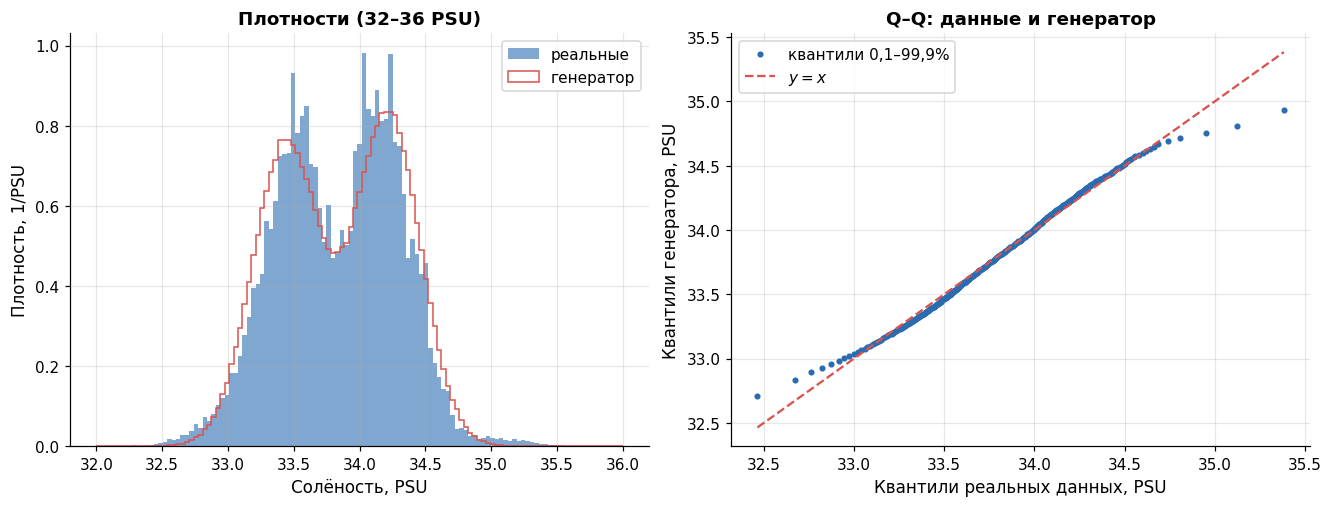

In [ ]:
#@title Реальные данные и генератор
bins = np.linspace(32, 36, 120)
q = np.linspace(.001, .999, 300)
qr, qg = np.quantile(salinity, q), np.quantile(generated, q)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(salinity, bins, density=True, color=BLUE, alpha=.6, label='реальные')
ax[0].hist(generated, bins, density=True, histtype='step', color=RED, lw=1.8, label='генератор')
ax[0].set(xlabel=XLABEL, ylabel='Плотность, 1/PSU', title='Плотности (32–36 PSU)')
ax[0].legend()
ax[1].plot(qr, qg, '.', color=BLUE, label='квантили 0,1–99,9%')
ax[1].plot([qr.min(), qr.max()], [qr.min(), qr.max()], '--', color=RED, label='$y=x$')
ax[1].set(xlabel='Квантили реальных данных, PSU', ylabel='Квантили генератора, PSU', title='Q–Q: данные и генератор')
ax[1].legend()
plt.show()

*Пояснение.* Левый график — совпадение формы двух пиков. Справа — квантиль к квантилю: чем ближе точки к диагонали, тем ближе распределения, а расхождения у краёв — это различие хвостов.

Двухвыборочный критерий Колмогорова–Смирнова: $D=\sup_x|F_1(x)-F_2(x)|$. При больших $n$ он замечает сколь угодно малые различия, поэтому смотрим и на $D$, и на $p$-value при разных объёмах выборок.

In [ ]:
#@title Критерий Колмогорова–Смирнова
rows = []
for n in [1_000, 5_000, 10_000, 50_000]:
    r = stats.ks_2samp(salinity.sample(n, random_state=1), generated[:n])
    rows.append({'n': n, 'D': r.statistic, 'p-value': r.pvalue})
display(pd.DataFrame(rows).set_index('n').style.format({'D': '{:.4f}', 'p-value': '{:.4f}'}))

,D,p-value
n,,
1000,0.0620,0.0428
5000,0.0480,0.0000
10000,0.0388,0.0000
50000,0.0345,0.0000


In [ ]:
#@title Автотесты генератора
make = lambda seed: SalinityMixtureGenerator(mu1, s1, mu2, s2, p1, seed)

def test_reproducible():
    assert np.array_equal(make(1).generate(100), make(1).generate(100))

def test_size_and_finite():
    a = make(2).generate(1000)
    assert a.shape == (1000,) and np.isfinite(a).all()

def test_std_normal():
    z = make(3).std_normal(500_000)
    assert abs(z.mean()) < 0.01 and abs(z.std() - 1) < 0.01

def test_mixture_moments():
    a = make(4).generate(500_000)
    var_th = p1 * s1**2 + (1 - p1) * s2**2 + p1 * (1 - p1) * (mu1 - mu2)**2
    assert abs(a.mean() - (p1 * mu1 + (1 - p1) * mu2)) < 5 * np.sqrt(var_th / len(a))
    assert abs(a.var() / var_th - 1) < 0.02

for t in (test_reproducible, test_size_and_finite, test_std_normal, test_mixture_moments):
    t()
    print('OK  ', t.__name__)

OK   test_reproducible
OK   test_size_and_finite
OK   test_std_normal
OK   test_mixture_moments


**Интерактивный подбор параметров.** Слайдеры меняют параметры генератора; в заголовке — статистика Колмогорова–Смирнова относительно реальной подвыборки.

In [ ]:
#@title Интерактивный генератор
import ipywidgets as w

real_sub = salinity.sample(20_000, random_state=0).to_numpy()

def show(p=p1, m1=mu1, sd1=s1, m2=mu2, sd2=s2):
    gen_ = SalinityMixtureGenerator(m1, sd1, m2, sd2, p, seed=0).generate(20_000)
    d = stats.ks_2samp(real_sub, gen_).statistic
    fig, ax = plt.subplots(figsize=(9, 4))
    b = np.linspace(32, 36, 100)
    ax.hist(real_sub, b, density=True, color=BLUE, alpha=.6, label='реальные')
    ax.hist(gen_, b, density=True, histtype='step', color=RED, lw=1.8, label='генератор')
    ax.set(xlabel=XLABEL, ylabel='Плотность, 1/PSU', title=f'KS: D = {d:.4f}')
    ax.legend()
    plt.show()

sl = lambda v, lo, hi, st: w.FloatSlider(value=v, min=lo, max=hi, step=st, continuous_update=False)
w.interact(show, p=sl(p1, .1, .9, .01), m1=sl(mu1, 32.5, 34, .01), sd1=sl(s1, .05, .6, .01),
           m2=sl(mu2, 33.5, 35, .01), sd2=sl(s2, .05, .6, .01));

interactive(children=(FloatSlider(value=0.4866931128586964, continuous_update=False, description='p', max=0.9,…

<a id="rv2-resume"></a>
### resume     

Почему такой генератор. Распределение солёности — это два горба, то есть смесь двух нормальных. Генератор делает два шага: «бросает монетку» и выбирает, из какого горба взять значение, потом получает нормальное число для этого горба методом Бокса–Мюллера. Метод простой, не требует сложных таблиц и по смыслу совпадает с тем, как устроены данные.

Совпадение метрик. Среднее и стандартное отклонение у генератора и реальных данных почти совпали, квартили, асимметрия и медиана тоже, проблема только у эксцесса. Это происходит, потому что у реальных данных есть выбросы с длинными хвостами (до 28.4 и до 37.0), а у нормальных горбов хвосты «лёгкие» (генератор почти не выдаёт такие редкие значения).Середина распределения воспроизведена хорошо, а края — хуже. Для асимметрии и эксцесса, близким к нулю, сравнивали абсолютную разность, а не процент: процент от числа, близкого к нулю, ничего не показывает.

Критерий Колмогорова–Смирнова. Статистика D (показывает расхождение функций распределения) получилась маленькой, p-value при больших n ещё меньше. Не доказывает, что генератор плохой: при большом объёме данных критерий замечает даже крошечные различия. Важнее, что D почти не растёт при росте n, а падает с 0.062 до 0.0345 и выходит на плато. Оно и связано с хвостами и формой пиков.

Q–Q график. Основная часть точек лежит на диагонали, большая часть распределений совпадает. Расхождения есть только в самых краях, где у реальных данных выбросы, а у генератора их нет, что согласуется с метриками.

Четыре автотеста прошли: генератор даёт одинаковый результат при одинаковом seed, возвращает нужное количество чисел без NaN и бесконечностей, стандартное нормальное число имеет среднее около 0 и σ около 1, а среднее и дисперсия смеси совпадают с теоретическими формулами.
Слайдеры позволяют двигать доли и параметры горбов и сразу видеть, как меняются график и D: при параметрах, взятых из данных, генератор совпадает с реальными данными.

[↑ К оглавлению](#toc)

<a id="s2-table"></a>
## Lab resume (sprint 2)

<a id="cat-table-2"></a>
### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|:------:|:--------------|:-----:|:--------|
| $X=\mu_K+\sigma_K Z$<br>$Z=\sqrt{-2\ln U_1}\,\cos 2\pi U_2$ | [math desc](#rv2-math), [code](#rv2-code) | $p_1=0.4867$<br>$\mu_{1,2}=33.4422;\ 34.2178$<br>$\sigma_{1,2}=0.2555;\ 0.2467$ | Метод суперпозиции + метод полярных координат (Бокс–Мюллер), класс `SalinityMixtureGenerator` |
| $\bar x$<br>$s$<br>$\gamma_1$<br>$\gamma_2$ | [tests](#rv2-tests) | 33.8404 / 33.8405<br>0.4618 / 0.4617<br>−0.0518 / −0.0589<br>0.0594 / −0.9873 | Реальные данные / генератор; хуже всего совпадает эксцесс (тяжёлые хвосты) |
| $D$<br>$p$-value | [tests](#rv2-tests) | 0.0620 / 0.0428<br>0.0388 / 0.0000<br>0.0345 / 0.0000 | Колмогоров–Смирнов при $n=1000;\ 10\,000;\ 50\,000$ |
| автотесты | [tests](#rv2-tests) | 4 из 4 | Повторяемость по seed, размер и конечность, стандартная нормаль, моменты смеси |
| интерактивность | [tests](#rv2-tests) | — | Слайдеры `ipywidgets` для параметров смеси |
| литература | [Литература](#refs) | 7 | Статьи, монографии и источник данных |


[↑ К оглавлению](#toc)

<a id="refs"></a>
## Литература

1. Box G. E. P., Muller M. E. A note on the generation of random normal deviates // Annals of Mathematical Statistics. 1958. Vol. 29, No. 2. P. 610–611.
2. Marsaglia G., Bray T. A. A convenient method for generating normal variables // SIAM Review. 1964. Vol. 6, No. 3. P. 260–264.
3. Devroye L. Non-Uniform Random Variate Generation. New York: Springer, 1986.
4. McLachlan G., Peel D. Finite Mixture Models. New York: Wiley, 2000.
5. Anderson T. W., Darling D. A. Asymptotic theory of certain "goodness of fit" criteria based on stochastic processes // Annals of Mathematical Statistics. 1952. Vol. 23, No. 2. P. 193–212.
6. O'Neill M. E. PCG: A family of simple fast space-efficient statistically good algorithms for random number generation. Harvey Mudd College, Tech. Rep. HMC-CS-2014-0905, 2014.
7. CalCOFI — California Cooperative Oceanic Fisheries Investigations, https://calcofi.org ; датасет `sohier/calcofi` на Kaggle.


[↑ К оглавлению](#toc)